In [1]:
import glob
import pandas as pd
import os
import pickle
import numpy as np

os.environ["PATH"] = os.path.expanduser("~/miniconda3/envs/fox_env24/bin") + ":" + os.environ["PATH"]
pd.options.mode.chained_assignment = None

# plotting packages
from bokeh.plotting import figure, show
from bokeh.io import export_svgs, output_notebook
output_notebook()
from bokeh.models import ColumnDataSource, ColorBar, Span, Label, Range1d
from bokeh.transform import factor_cmap
from bokeh.models import Legend
from scipy.spatial import ConvexHull
from scipy.interpolate import splprep, splev

palette_hex = [
    "#73b9a5", "#a33f3e", "#2261b2", "#fea17b", "#c5aedf",
    "#d4af9e", "#fea8d4", "#7e5679", "#6ea9fd", "#bd8985",
    "#d36d54", "#e4d177", "#89aeb3", "#fec4a7", "#977d89",
    "#637fd0", "#93581c", "#4bcbfe", "#82e2dd", "#dea257",
    "#70715d", "#009aa5", "#c27869", "#a893c6", "#00eafa",
    "#a96296", "#769be0", "#aa5839", "#7dcab8", "#847ebb",
    "#f28679", "#286958", "#00838d", "#b9989c", "#de8a5c",
    "#e3c7fe", "#97792d", "#6d6cb7", "#8e586f", "#b9d08a",
    "#a8a6e3", "#c35653", "#50729f", "#70548b", "#575a99",
    "#b26270", "#a58d39", "#9cc2c8", "#c0af85", "#72999a",
    "#5ebafe", "#59d6ac", "#984649", "#1bb1ca", "#c99b89",
    "#8fe7a1", "#568972", "#6690e7", "#e5b76b", "#798258",
    "#9984aa", "#a9dfc8", "#567319", "#cd8b68", "#979bb7",
    "#b17981", "#bacde7", "#8c6d80", "#576424", "#cfbe91",
    "#b2abca", "#e6bcb3", "#9783cf", "#2e9096", "#bd6c41",
]

plot_hull = False
plot_other_chr = True

path = '/home/jjfox/resnick_ci2_gbm_/Data/DNA_data/'

# get all files
files = glob.glob(f"{path}/*assigned.csv")

# only keep 1 patient sample
patient_id = '4555'
files = [i for i in files if patient_id in i]

# load data
df_1 = pd.read_csv(files[0], low_memory=False)

# fix chromosomes
probe_df = pd.read_csv("/resnick/groups/CaiLab/jjfox/copied_from_central/DNA_seqFISH/human/24-12-19_human_genome_DNA_seqFISH_final_probes.csv")
df_unique = probe_df.drop_duplicates(subset='bin_name', keep='last')
chr_dict = dict(zip(df_unique['bin_name'], df_unique['chr']))

df_1["blockbin"] = (
    df_1["block_assigned"].str.replace("block_", "block", regex=False)
    + "_" +
    df_1["name"].str.replace("bin_", "bin", regex=False)
)
df_1['chromosome_true'] = df_1.blockbin.map(chr_dict)

# map chromosome arms
with open('chrom_arm_dict.pkl', 'rb') as f:
    chrom_arm_dict = pickle.load(f)

df_1['chrom_arm'] = df_1.blockbin.map(chrom_arm_dict)

# load cell type data
celltype_df = pd.read_csv('/resnick/groups/mthomson/ci2_data/CaiLab/gbm/dna_distance_data/V2_24_patients_Obj_mapped.csv', low_memory=False)
celltype_df.columns = [col.replace('.', '_') for col in celltype_df.columns]
celltype_df.rename(columns={'Unnamed: 0': 'cell_id'}, inplace=True)
gbm_cells = celltype_df.loc[celltype_df['ID'] == patient_id].copy()
gbm_cells['cell_id'] = gbm_cells['cell_id'].apply(lambda x: int(x.split('_')[0]))
gbm_cell_dict = dict(zip(gbm_cells['cell_id'], gbm_cells['predicted_celltype']))
df_1['predicted_celltype'] = df_1['matched_label'].map(gbm_cell_dict)
celltypes = df_1['predicted_celltype'].unique()


def compute_scale_bar(shared_x_range, shared_y_range, scale_bar_length=2, inset_frac=0.04):
    plot_x_min, plot_x_max = shared_x_range
    plot_y_min, plot_y_max = shared_y_range
    plot_x_span = plot_x_max - plot_x_min
    plot_y_span = plot_y_max - plot_y_min
    bar_inset_x = inset_frac * plot_x_span
    bar_inset_y = inset_frac * plot_y_span
    bar_x_end = plot_x_max - bar_inset_x
    bar_x_start = bar_x_end - scale_bar_length
    bar_y = plot_y_min + bar_inset_y
    return bar_x_start, bar_x_end, bar_y


def add_scale_bar(p, bar_x_start, bar_x_end, bar_y):
    p.line([bar_x_start, bar_x_end], [bar_y, bar_y], line_width=3, line_color="black")
    p.add_layout(Label(
        x=(bar_x_start + bar_x_end) / 2, y=bar_y,
        text="2 \u03bcm", text_align="center", text_baseline="bottom",
        text_color="black", text_font_size="10pt", y_offset=2))


def clean_axes(p):
    p.xaxis.axis_label = None
    p.yaxis.axis_label = None
    p.xgrid.grid_line_color = None
    p.ygrid.grid_line_color = None
    p.xaxis.major_label_text_font_size = "0pt"
    p.yaxis.major_label_text_font_size = "0pt"
    p.xaxis.major_tick_line_color = None
    p.xaxis.minor_tick_line_color = None
    p.yaxis.major_tick_line_color = None
    p.yaxis.minor_tick_line_color = None
    p.xaxis.axis_line_color = None
    p.yaxis.axis_line_color = None
    p.title.text_color = "white"


def sort_chromosomes(unique_chrs):
    unique_chrs = list(unique_chrs)
    unique_chrs.sort(key=lambda x: x.split('chr')[1])
    unique_chrs_num = unique_chrs[:-2]
    unique_chrs_num.sort(key=lambda x: int(x.split('chr')[1]))
    return unique_chrs_num + [unique_chrs[-2]] + [unique_chrs[-1]]


def compute_hull(df_cell, hull_gap=0.15):
    all_points = np.column_stack([df_cell['x'].values, df_cell['y'].values])
    hull = ConvexHull(all_points)
    hull_verts = all_points[hull.vertices]
    centroid = hull_verts.mean(axis=0)
    directions = hull_verts - centroid
    directions = directions / np.linalg.norm(directions, axis=1, keepdims=True)
    hull_verts_expanded = hull_verts + directions * hull_gap
    hull_verts_closed = np.vstack([hull_verts_expanded, hull_verts_expanded[0]])
    tck, u = splprep([hull_verts_closed[:, 0], hull_verts_closed[:, 1]], s=0, per=True, k=3)
    u_fine = np.linspace(0, 1, 300)
    hull_xs, hull_ys = splev(u_fine, tck)
    return list(hull_xs), list(hull_ys)


def compute_shared_range(df_cell, pad_frac=0.05):
    x_min, x_max = df_cell['x'].min(), df_cell['x'].max()
    y_min, y_max = df_cell['y'].min(), df_cell['y'].max()
    x_span = x_max - x_min
    y_span = y_max - y_min
    max_span = max(x_span, y_span)
    x_center = (x_min + x_max) / 2
    y_center = (y_min + y_max) / 2
    pad = pad_frac * max_span
    shared_x_range = (x_center - max_span/2 - pad, x_center + max_span/2 + pad)
    shared_y_range = (y_center - max_span/2 - pad, y_center + max_span/2 + pad)
    return shared_x_range, shared_y_range


def plot_cell(df_1, cell, label, out_dir, plot_hull=True, plot_other_chr=True, plot_size=670, scale_bar_length=2):
    df_cell = df_1.loc[df_1['matched_label'] == cell].copy()
    df_cell = df_cell[df_cell['chromosome_true'].notna()]

    shared_x_range, shared_y_range = compute_shared_range(df_cell)
    hull_xs, hull_ys = compute_hull(df_cell)
    bar_x_start, bar_x_end, bar_y = compute_scale_bar(shared_x_range, shared_y_range, scale_bar_length)

    unique_chrs = sort_chromosomes(df_cell['chromosome_true'].unique())
    palette = palette_hex[:len(unique_chrs)]

    # Plot 1: Chromosome scatter
    p = figure(title=f"Scatterplot by Chromosome Cell {cell}",
               width=plot_size, height=plot_size,
               background_fill_color="white",
               border_fill_color="white",
               outline_line_color=None,
               x_range=Range1d(start=shared_x_range[0], end=shared_x_range[1]),
               y_range=Range1d(start=shared_y_range[0], end=shared_y_range[1]))

    for chr_value, color in zip(unique_chrs, palette):
        chr_source = ColumnDataSource(df_cell[df_cell['chromosome_true'] == chr_value])
        p.scatter('x', 'y', source=chr_source, size=13, fill_alpha=0.8, color=color)

    if plot_hull:
        p.line(hull_xs, hull_ys, line_width=1.5, line_color="black", line_dash="dashed")
    
    clean_axes(p)
    add_scale_bar(p, bar_x_start, bar_x_end, bar_y)
    show(p)
    #p.output_backend = "svg"
    #export_svgs(p, filename=f"{out_dir}/{label}_chromosomes.svg")

    # Plot 2: Translocation scatter
    p2 = figure(title=f"Translocation Scatterplot {cell}",
               width=plot_size, height=plot_size,
               background_fill_color="white",
               border_fill_color="white",
               outline_line_color=None,
               x_range=Range1d(start=shared_x_range[0], end=shared_x_range[1]),
               y_range=Range1d(start=shared_y_range[0], end=shared_y_range[1]))
    
    highlight_chrs = ['chr3', 'chr10']

    # plot other chromosomes as gray
    for chr_value in unique_chrs:
        if chr_value in highlight_chrs:
            continue
        chr_source = ColumnDataSource(df_cell[df_cell['chromosome_true'] == chr_value])
        bg_color = '#CCCCCC' if plot_other_chr else '#FFFFFF'
        p2.scatter('x', 'y', source=chr_source, size=13, fill_alpha=0.8, color=bg_color)

    # plot highlighted chromosomes
    for chr_value, color in zip(unique_chrs, palette):
        if chr_value not in highlight_chrs:
            continue
        chr_source = ColumnDataSource(df_cell[df_cell['chromosome_true'] == chr_value])
        p2.scatter('x', 'y', source=chr_source, size=13, fill_alpha=0.8, color=color)

    if plot_hull:
        p2.line(hull_xs, hull_ys, line_width=1.5, line_color="black", line_dash="dashed")
    
    clean_axes(p2)
    add_scale_bar(p2, bar_x_start, bar_x_end, bar_y)
    show(p2)
    #p2.output_backend = "svg"
    #export_svgs(p2, filename=f"{out_dir}/{label}_translocation.svg")




Loading BokehJS ...

In [2]:
out_dir = "../../../figures/Figure_2/Figure_2F"
os.makedirs(out_dir, exist_ok=True)

#plot_cell(df_1, cell=78, label="2543_T",        out_dir=out_dir, plot_hull=plot_hull, plot_other_chr=plot_other_chr)

In [3]:
# change to ecDNA

def plot_cell(df_1, cell, label, out_dir, plot_hull=True, plot_other_chr=True, plot_size=670, scale_bar_length=2):
    df_cell = df_1.loc[df_1['matched_label'] == cell].copy()
    df_notchr = df_cell[~df_cell['chromosome_true'].notna()].copy()
    df_cell = df_cell[df_cell['chromosome_true'].notna()]

    shared_x_range, shared_y_range = compute_shared_range(df_cell)
    hull_xs, hull_ys = compute_hull(df_cell)
    bar_x_start, bar_x_end, bar_y = compute_scale_bar(shared_x_range, shared_y_range, scale_bar_length)

    unique_chrs = sort_chromosomes(df_cell['chromosome_true'].unique())
    palette = palette_hex[:len(unique_chrs)]

    # Plot 1: Chromosome scatter
    p = figure(title=f"Scatterplot by Chromosome Cell {cell}",
               width=plot_size, height=plot_size,
               background_fill_color="white",
               border_fill_color="white",
               outline_line_color=None,
               x_range=Range1d(start=shared_x_range[0], end=shared_x_range[1]),
               y_range=Range1d(start=shared_y_range[0], end=shared_y_range[1]))

    for chr_value, color in zip(unique_chrs, palette):
        chr_source = ColumnDataSource(df_cell[df_cell['chromosome_true'] == chr_value])
        p.scatter('x', 'y', source=chr_source, size=13, fill_alpha=0.8, color=color)

    if plot_hull:
        p.line(hull_xs, hull_ys, line_width=1.5, line_color="black", line_dash="dashed")
    
    clean_axes(p)
    add_scale_bar(p, bar_x_start, bar_x_end, bar_y)
    show(p)
    #p.output_backend = "svg"
    #export_svgs(p, filename=f"{out_dir}/{label}_chromosomes.svg")

    # Plot 2: ecDNA scatter
    p2 = figure(title=f"ecDNA Scatterplot {cell}",
               width=plot_size, height=plot_size,
               background_fill_color="white",
               border_fill_color="white",
               outline_line_color=None,
               x_range=Range1d(start=shared_x_range[0], end=shared_x_range[1]),
               y_range=Range1d(start=shared_y_range[0], end=shared_y_range[1]))
    
    highlight_chrs = ['chr7']
    ecDNA = 'EGFR'

    # plot other chromosomes as gray
    for chr_value in unique_chrs:
        if chr_value in highlight_chrs:
            continue
        chr_source = ColumnDataSource(df_cell[df_cell['chromosome_true'] == chr_value])
        bg_color = '#CCCCCC' if plot_other_chr else '#FFFFFF'
        p2.scatter('x', 'y', source=chr_source, size=13, fill_alpha=0.8, color=bg_color)

    # plot highlighted chromosomes
    for chr_value, color in zip(unique_chrs, palette):
        if chr_value not in highlight_chrs:
            continue
        chr_source = ColumnDataSource(df_cell[df_cell['chromosome_true'] == chr_value])
        p2.scatter('x', 'y', source=chr_source, size=13, fill_alpha=0.8, color=color)

    # plot ecDNA
    ecDNA_source = ColumnDataSource(df_notchr[df_notchr['name'] == ecDNA])
    p2.scatter('x', 'y', source=ecDNA_source, size=13, fill_alpha=0.8, color=palette_hex[41])

    if plot_hull:
        p2.line(hull_xs, hull_ys, line_width=1.5, line_color="black", line_dash="dashed")
    
    clean_axes(p2)
    add_scale_bar(p2, bar_x_start, bar_x_end, bar_y)
    show(p2)
    #p2.output_backend = "svg"
    #export_svgs(p2, filename=f"{out_dir}/{label}_translocation.svg")

#plot_cell(df_1, cell=78, label="2543_T",        out_dir=out_dir, plot_hull=plot_hull, plot_other_chr=plot_other_chr)

In [4]:
df_1.loc[df_1['predicted_celltype']=='OPC'].matched_label.value_counts()[:30]

matched_label
129229    23003
27172     20961
130515    20217
120792    17901
85021     17486
42136     16732
78339     16659
30005     16659
58243     16568
76214     16535
48793     16278
113619    16026
50534     15946
120974    15864
47370     15660
59354     15486
51778     15256
53020     15019
42179     14964
33594     14892
38072     14884
49250     14759
29727     14639
46862     14565
104204    14450
50760     14356
65646     14296
25991     14219
120563    14158
41872     14064
Name: count, dtype: int64

In [8]:
counts = df_1.loc[df_1['predicted_celltype'] == 'OPC'].matched_label.value_counts()
median_idx = counts.argsort()[::-1].values.tolist().index(counts.index.get_loc(counts.index[len(counts)//2]))
mid = len(counts) // 2
print(counts.iloc[mid-10:mid+10])

matched_label
91842     3140
43328     3140
28638     3139
111346    3139
34921     3139
115005    3138
60689     3138
63110     3138
84620     3138
33916     3138
86314     3138
46387     3138
47705     3137
61626     3136
124412    3136
84345     3136
131229    3136
35963     3136
34836     3135
35386     3135
Name: count, dtype: int64


In [16]:
plot_cell(df_1, cell=91842, label=f"{patient_id}_OPC",        out_dir=out_dir, plot_hull=plot_hull, plot_other_chr=plot_other_chr)

In [ ]:
plot_cell(df_1, cell=201, label="3883_OPC",        out_dir=out_dir, plot_hull=plot_hull, plot_other_chr=plot_other_chr)

In [34]:
# get all files
files = glob.glob(f"{path}/*assigned.csv")

# only keep 1 patient sample
patient_id = '5597'
files = [i for i in files if patient_id in i]

# load data
df_1 = pd.read_csv(files[0], low_memory=False)

# fix chromosomes
probe_df = pd.read_csv("/resnick/groups/CaiLab/jjfox/copied_from_central/DNA_seqFISH/human/24-12-19_human_genome_DNA_seqFISH_final_probes.csv")
df_unique = probe_df.drop_duplicates(subset='bin_name', keep='last')
chr_dict = dict(zip(df_unique['bin_name'], df_unique['chr']))

df_1["blockbin"] = (
    df_1["block_assigned"].str.replace("block_", "block", regex=False)
    + "_" +
    df_1["name"].str.replace("bin_", "bin", regex=False)
)
df_1['chromosome_true'] = df_1.blockbin.map(chr_dict)

# map chromosome arms
with open('chrom_arm_dict.pkl', 'rb') as f:
    chrom_arm_dict = pickle.load(f)

df_1['chrom_arm'] = df_1.blockbin.map(chrom_arm_dict)

# load cell type data
celltype_df = pd.read_csv('/resnick/groups/mthomson/ci2_data/CaiLab/gbm/dna_distance_data/V2_24_patients_Obj_mapped.csv', low_memory=False)
celltype_df.columns = [col.replace('.', '_') for col in celltype_df.columns]
celltype_df.rename(columns={'Unnamed: 0': 'cell_id'}, inplace=True)
gbm_cells = celltype_df.loc[celltype_df['ID'] == patient_id].copy()
gbm_cells['cell_id'] = gbm_cells['cell_id'].apply(lambda x: int(x.split('_')[0]))
gbm_cell_dict = dict(zip(gbm_cells['cell_id'], gbm_cells['predicted_celltype']))
df_1['predicted_celltype'] = df_1['matched_label'].map(gbm_cell_dict)
celltypes = df_1['predicted_celltype'].unique()

In [35]:
df_1.loc[df_1['predicted_celltype']=='OPC'].matched_label.value_counts()[:30]

matched_label
4827    8337
3967    7251
4576    6908
2327    6906
5473    6903
1297    6053
2045    6006
3470    5961
5436    5827
5448    5647
3208    5643
1211    5440
2880    5400
1529    5346
2866    5275
399     5162
5544    5110
2862    5047
3100    4783
2365    4726
1428    4663
2716    4625
4427    4616
4639    4592
3599    4573
2979    4551
1929    4527
2061    4501
379     4493
4276    4449
Name: count, dtype: int64

In [36]:
plot_cell(df_1, cell=1211, label="3883_OPC",        out_dir=out_dir, plot_hull=plot_hull, plot_other_chr=plot_other_chr)

In [37]:
plot_cell(df_1, cell=2880, label="3883_OPC",        out_dir=out_dir, plot_hull=plot_hull, plot_other_chr=plot_other_chr)

In [38]:
plot_cell(df_1, cell=1529, label="3883_OPC",        out_dir=out_dir, plot_hull=plot_hull, plot_other_chr=plot_other_chr)

# violin plot

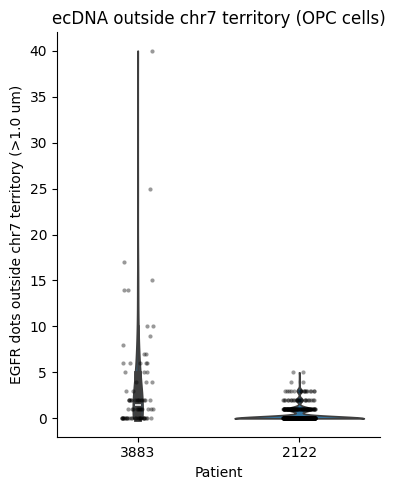

In [13]:
import glob
import os
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial import cKDTree

os.environ["PATH"] = os.path.expanduser("~/miniconda3/envs/fox_env24/bin") + ":" + os.environ["PATH"]
pd.options.mode.chained_assignment = None

# ---------------------------------------------------------------------------
# Configuration
# ---------------------------------------------------------------------------
DATA_PATH = "/home/jjfox/resnick_ci2_gbm_/Data/DNA_data/"
PROBE_CSV = "/resnick/groups/CaiLab/jjfox/copied_from_central/DNA_seqFISH/human/24-12-19_human_genome_DNA_seqFISH_final_probes.csv"
CELLTYPE_CSV = "/resnick/groups/mthomson/ci2_data/CaiLab/gbm/dna_distance_data/V2_24_patients_Obj_mapped.csv"
CHROM_ARM_DICT_PKL = "chrom_arm_dict.pkl"
OUT_DIR = "../../../figures/Figure_2/Figure_2F"

PATIENT_IDS = ["3883", "2122"]
CELLTYPE_FILTER = "OPC"
TARGET_CHR = "chr7"
ECDNA_NAME = "EGFR"
TERRITORY_RADIUS = 1.0  # um


# ---------------------------------------------------------------------------
# Data loading
# ---------------------------------------------------------------------------
def build_chr_dict():
    probe_df = pd.read_csv(PROBE_CSV)
    df_unique = probe_df.drop_duplicates(subset="bin_name", keep="last")
    return dict(zip(df_unique["bin_name"], df_unique["chr"]))


def load_chrom_arm_dict():
    with open(CHROM_ARM_DICT_PKL, "rb") as f:
        return pickle.load(f)


def load_patient(patient_id, chr_dict, chrom_arm_dict):
    files = [f for f in glob.glob(f"{DATA_PATH}/*assigned.csv") if patient_id in f]
    df = pd.read_csv(files[0], low_memory=False)

    df["blockbin"] = (
        df["block_assigned"].str.replace("block_", "block", regex=False)
        + "_"
        + df["name"].str.replace("bin_", "bin", regex=False)
    )
    df["chromosome_true"] = df["blockbin"].map(chr_dict)
    df["chrom_arm"] = df["blockbin"].map(chrom_arm_dict)

    celltype_df = pd.read_csv(CELLTYPE_CSV, low_memory=False)
    celltype_df.columns = [col.replace(".", "_") for col in celltype_df.columns]
    celltype_df.rename(columns={"Unnamed: 0": "cell_id"}, inplace=True)
    gbm_cells = celltype_df.loc[celltype_df["ID"] == patient_id].copy()
    gbm_cells["cell_id"] = gbm_cells["cell_id"].apply(lambda x: int(x.split("_")[0]))
    cell_dict = dict(zip(gbm_cells["cell_id"], gbm_cells["predicted_celltype"]))
    df["predicted_celltype"] = df["matched_label"].map(cell_dict)

    return df


# ---------------------------------------------------------------------------
# Count EGFR dots outside chr7 territory per cell
# ---------------------------------------------------------------------------
def count_egfr_outside_territory(df, radius=TERRITORY_RADIUS):
    """For each cell, count EGFR dots farther than `radius` from any chr7 dot."""
    opc_cells = df.loc[df["predicted_celltype"] == CELLTYPE_FILTER, "matched_label"].unique()
    records = []

    for cell in opc_cells:
        df_cell = df.loc[df["matched_label"] == cell]

        # chr7 dots (assigned to chromosome)
        chr7 = df_cell.loc[df_cell["chromosome_true"] == TARGET_CHR, ["x", "y", "z"]]
        # EGFR dots (unassigned / ecDNA)
        egfr = df_cell.loc[
            (df_cell["chromosome_true"].isna()) & (df_cell["name"] == ECDNA_NAME),
            ["x", "y", "z"],
        ]

        if len(chr7) == 0 or len(egfr) == 0:
            continue

        # Build KDTree from chr7 positions, query each EGFR dot
        tree = cKDTree(chr7.values)
        dists, _ = tree.query(egfr.values)

        n_outside = int((dists > radius).sum())
        n_total = len(egfr)

        records.append({
            "cell": cell,
            "n_egfr_total": n_total,
            "n_egfr_outside": n_outside,
        })

    return pd.DataFrame(records)


# ---------------------------------------------------------------------------
# Main
# ---------------------------------------------------------------------------
chr_dict = build_chr_dict()
chrom_arm_dict = load_chrom_arm_dict()

results = []
for pid in PATIENT_IDS:
    df = load_patient(pid, chr_dict, chrom_arm_dict)
    counts = count_egfr_outside_territory(df)
    counts["patient"] = pid
    results.append(counts)

results_df = pd.concat(results, ignore_index=True)

# ---------------------------------------------------------------------------
# Violin plot
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(4, 5))
sns.violinplot(
    data=results_df,
    x="patient",
    y="n_egfr_outside",
    ax=ax,
    inner="box",
    cut=0,
)
sns.stripplot(
    data=results_df,
    x="patient",
    y="n_egfr_outside",
    ax=ax,
    color="black",
    size=3,
    alpha=0.4,
    jitter=True,
)
ax.set_xlabel("Patient")
ax.set_ylabel(f"EGFR dots outside {TARGET_CHR} territory (>{TERRITORY_RADIUS} um)")
ax.set_title(f"ecDNA outside {TARGET_CHR} territory ({CELLTYPE_FILTER} cells)")
sns.despine()
plt.tight_layout()

os.makedirs(OUT_DIR, exist_ok=True)
#fig.savefig(f"{OUT_DIR}/egfr_outside_chr7_violin.svg")
#fig.savefig(f"{OUT_DIR}/egfr_outside_chr7_violin.png", dpi=300)
plt.show()

In [ ]:
from scipy.stats import mannwhitneyu

group_3883 = results_df.loc[results_df["patient"] == "3883", "n_egfr_outside"]
group_5597 = results_df.loc[results_df["patient"] == "5597", "n_egfr_outside"]

stat, pval = mannwhitneyu(group_3883, group_5597, alternative="two-sided")
print(f"Mann-Whitney U test: U={stat:.1f}, p={pval:.4e}")
print(f"  3883 (n={len(group_3883)}): median={group_3883.median():.1f}, mean={group_3883.mean():.2f}")
print(f"  5597 (n={len(group_5597)}): median={group_5597.median():.1f}, mean={group_5597.mean():.2f}")

In [17]:
path = '/home/jjfox/resnick_ci2_gbm_/Data/DNA_data/'

# get all files
files = glob.glob(f"{path}/*assigned.csv")

In [19]:
samples = [i.split('DNA_data/')[1].split('_allTranscripts')[0] for i in files]

In [20]:
samples

['19AF747',
 '2122',
 '2543',
 '2683',
 '2789',
 '2830',
 '3097_1',
 '3209',
 '3364',
 '3557',
 '3703',
 '3754',
 '3825',
 '3883',
 '4250',
 '4477',
 '4482_2',
 '4494_1',
 '4494_2',
 '4523',
 '4555',
 '4590',
 '4668',
 '4904',
 '4970',
 '5121',
 '5201',
 '5272_1',
 '5272_2',
 '5538_1',
 '5538_2',
 '5541_1',
 '5541_2',
 '5597',
 'g34011']

In [ ]:
import glob
import os
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial import cKDTree
import tqdm

os.environ["PATH"] = os.path.expanduser("~/miniconda3/envs/fox_env24/bin") + ":" + os.environ["PATH"]
pd.options.mode.chained_assignment = None

# ---------------------------------------------------------------------------
# Configuration
# ---------------------------------------------------------------------------
DATA_PATH = "/home/jjfox/resnick_ci2_gbm_/Data/DNA_data/"
PROBE_CSV = "/resnick/groups/CaiLab/jjfox/copied_from_central/DNA_seqFISH/human/24-12-19_human_genome_DNA_seqFISH_final_probes.csv"
CELLTYPE_CSV = "/resnick/groups/mthomson/ci2_data/CaiLab/gbm/dna_distance_data/V2_24_patients_Obj_mapped.csv"
CHROM_ARM_DICT_PKL = "chrom_arm_dict.pkl"
OUT_DIR = "../../../figures/Figure_2/Figure_2F"

PATIENT_IDS = samples
CELLTYPE_FILTER = "OPC"
TARGET_CHR = "chr7"
ECDNA_NAME = "EGFR"
TERRITORY_RADIUS = 1.0  # um


# ---------------------------------------------------------------------------
# Data loading
# ---------------------------------------------------------------------------
def build_chr_dict():
    probe_df = pd.read_csv(PROBE_CSV)
    df_unique = probe_df.drop_duplicates(subset="bin_name", keep="last")
    return dict(zip(df_unique["bin_name"], df_unique["chr"]))


def load_chrom_arm_dict():
    with open(CHROM_ARM_DICT_PKL, "rb") as f:
        return pickle.load(f)


def load_patient(patient_id, chr_dict, chrom_arm_dict):
    files = [f for f in glob.glob(f"{DATA_PATH}/*assigned.csv") if patient_id in f]
    df = pd.read_csv(files[0], low_memory=False)

    df["blockbin"] = (
        df["block_assigned"].str.replace("block_", "block", regex=False)
        + "_"
        + df["name"].str.replace("bin_", "bin", regex=False)
    )
    df["chromosome_true"] = df["blockbin"].map(chr_dict)
    df["chrom_arm"] = df["blockbin"].map(chrom_arm_dict)

    celltype_df = pd.read_csv(CELLTYPE_CSV, low_memory=False)
    celltype_df.columns = [col.replace(".", "_") for col in celltype_df.columns]
    celltype_df.rename(columns={"Unnamed: 0": "cell_id"}, inplace=True)
    gbm_cells = celltype_df.loc[celltype_df["ID"] == patient_id].copy()
    gbm_cells["cell_id"] = gbm_cells["cell_id"].apply(lambda x: int(x.split("_")[0]))
    cell_dict = dict(zip(gbm_cells["cell_id"], gbm_cells["predicted_celltype"]))
    df["predicted_celltype"] = df["matched_label"].map(cell_dict)

    return df


# ---------------------------------------------------------------------------
# Count EGFR dots outside chr7 territory per cell
# ---------------------------------------------------------------------------
def count_egfr_outside_territory(df, radius=TERRITORY_RADIUS):
    """For each cell, count EGFR dots farther than `radius` from any chr7 dot."""
    opc_cells = df.loc[df["predicted_celltype"] == CELLTYPE_FILTER, "matched_label"].unique()
    records = []

    for cell in opc_cells:
        df_cell = df.loc[df["matched_label"] == cell]

        # chr7 dots (assigned to chromosome)
        chr7 = df_cell.loc[df_cell["chromosome_true"] == TARGET_CHR, ["x", "y", "z"]]
        # EGFR dots (unassigned / ecDNA)
        egfr = df_cell.loc[
            (df_cell["chromosome_true"].isna()) & (df_cell["name"] == ECDNA_NAME),
            ["x", "y", "z"],
        ]

        if len(chr7) == 0 or len(egfr) == 0:
            continue

        # Build KDTree from chr7 positions, query each EGFR dot
        tree = cKDTree(chr7.values)
        dists, _ = tree.query(egfr.values)

        n_outside = int((dists > radius).sum())
        n_total = len(egfr)

        records.append({
            "cell": cell,
            "n_egfr_total": n_total,
            "n_egfr_outside": n_outside,
        })

    return pd.DataFrame(records)


# ---------------------------------------------------------------------------
# Main
# ---------------------------------------------------------------------------
chr_dict = build_chr_dict()
chrom_arm_dict = load_chrom_arm_dict()

results = []
for pid in tqdm.tqdm(PATIENT_IDS):
    try:
        df = load_patient(pid, chr_dict, chrom_arm_dict)
        counts = count_egfr_outside_territory(df)
        counts["patient"] = pid
        results.append(counts)
    except Exception as e:
        print(f"Skipping patient {pid}: {e}")
        continue

results_df = pd.concat(results, ignore_index=True)

# ---------------------------------------------------------------------------
# Violin plot
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(max(4, len(results_df["patient"].unique()) * 1.5), 5))
sns.violinplot(
    data=results_df,
    x="patient",
    y="n_egfr_outside",
    ax=ax,
    inner="box",
    cut=0,
)
sns.stripplot(
    data=results_df,
    x="patient",
    y="n_egfr_outside",
    ax=ax,
    color="black",
    size=3,
    alpha=0.4,
    jitter=True,
)
ax.set_xlabel("Patient")
ax.set_ylabel(f"EGFR dots outside {TARGET_CHR} territory (>{TERRITORY_RADIUS} um)")
ax.set_title(f"ecDNA outside {TARGET_CHR} territory ({CELLTYPE_FILTER} cells)")
sns.despine()
plt.tight_layout()

os.makedirs(OUT_DIR, exist_ok=True)
#fig.savefig(f"{OUT_DIR}/egfr_outside_chr7_violin.svg")
#fig.savefig(f"{OUT_DIR}/egfr_outside_chr7_violin.png", dpi=300)
plt.show()

 57%|█████▋    | 20/35 [1:17:10<1:37:59, 391.95s/it]

In [1]:
plt.show()

NameError: name 'plt' is not defined

# Look at CCND2 amplification

In [14]:
import glob
import pandas as pd
import os
import pickle
import numpy as np

os.environ["PATH"] = os.path.expanduser("~/miniconda3/envs/fox_env24/bin") + ":" + os.environ["PATH"]
pd.options.mode.chained_assignment = None

# plotting packages
from bokeh.plotting import figure, show
from bokeh.io import export_svgs, output_notebook
output_notebook()
from bokeh.models import ColumnDataSource, ColorBar, Span, Label, Range1d
from bokeh.transform import factor_cmap
from bokeh.models import Legend
from scipy.spatial import ConvexHull
from scipy.interpolate import splprep, splev

palette_hex = [
    "#73b9a5", "#a33f3e", "#2261b2", "#fea17b", "#c5aedf",
    "#d4af9e", "#fea8d4", "#7e5679", "#6ea9fd", "#bd8985",
    "#d36d54", "#e4d177", "#89aeb3", "#fec4a7", "#977d89",
    "#637fd0", "#93581c", "#4bcbfe", "#82e2dd", "#dea257",
    "#70715d", "#009aa5", "#c27869", "#a893c6", "#00eafa",
    "#a96296", "#769be0", "#aa5839", "#7dcab8", "#847ebb",
    "#f28679", "#286958", "#00838d", "#b9989c", "#de8a5c",
    "#e3c7fe", "#97792d", "#6d6cb7", "#8e586f", "#b9d08a",
    "#a8a6e3", "#c35653", "#50729f", "#70548b", "#575a99",
    "#b26270", "#a58d39", "#9cc2c8", "#c0af85", "#72999a",
    "#5ebafe", "#59d6ac", "#984649", "#1bb1ca", "#c99b89",
    "#8fe7a1", "#568972", "#6690e7", "#e5b76b", "#798258",
    "#9984aa", "#a9dfc8", "#567319", "#cd8b68", "#979bb7",
    "#b17981", "#bacde7", "#8c6d80", "#576424", "#cfbe91",
    "#b2abca", "#e6bcb3", "#9783cf", "#2e9096", "#bd6c41",
]

plot_hull = False
plot_other_chr = True

path = '/home/jjfox/resnick_ci2_gbm_/Data/DNA_data/'

# get all files
files = glob.glob(f"{path}/*assigned.csv")

# only keep 1 patient sample
patient_id = '2830'
files = [i for i in files if patient_id in i]

# load data
df_1 = pd.read_csv(files[0], low_memory=False)

# fix chromosomes
probe_df = pd.read_csv("/resnick/groups/CaiLab/jjfox/copied_from_central/DNA_seqFISH/human/24-12-19_human_genome_DNA_seqFISH_final_probes.csv")
df_unique = probe_df.drop_duplicates(subset='bin_name', keep='last')
chr_dict = dict(zip(df_unique['bin_name'], df_unique['chr']))

df_1["blockbin"] = (
    df_1["block_assigned"].str.replace("block_", "block", regex=False)
    + "_" +
    df_1["name"].str.replace("bin_", "bin", regex=False)
)
df_1['chromosome_true'] = df_1.blockbin.map(chr_dict)

# map chromosome arms
with open('chrom_arm_dict.pkl', 'rb') as f:
    chrom_arm_dict = pickle.load(f)

df_1['chrom_arm'] = df_1.blockbin.map(chrom_arm_dict)

# load cell type data
celltype_df = pd.read_csv('/resnick/groups/mthomson/ci2_data/CaiLab/gbm/dna_distance_data/V2_24_patients_Obj_mapped.csv', low_memory=False)
celltype_df.columns = [col.replace('.', '_') for col in celltype_df.columns]
celltype_df.rename(columns={'Unnamed: 0': 'cell_id'}, inplace=True)
gbm_cells = celltype_df.loc[celltype_df['ID'] == patient_id].copy()
gbm_cells['cell_id'] = gbm_cells['cell_id'].apply(lambda x: int(x.split('_')[0]))
gbm_cell_dict = dict(zip(gbm_cells['cell_id'], gbm_cells['predicted_celltype']))
df_1['predicted_celltype'] = df_1['matched_label'].map(gbm_cell_dict)
celltypes = df_1['predicted_celltype'].unique()


def compute_scale_bar(shared_x_range, shared_y_range, scale_bar_length=2, inset_frac=0.04):
    plot_x_min, plot_x_max = shared_x_range
    plot_y_min, plot_y_max = shared_y_range
    plot_x_span = plot_x_max - plot_x_min
    plot_y_span = plot_y_max - plot_y_min
    bar_inset_x = inset_frac * plot_x_span
    bar_inset_y = inset_frac * plot_y_span
    bar_x_end = plot_x_max - bar_inset_x
    bar_x_start = bar_x_end - scale_bar_length
    bar_y = plot_y_min + bar_inset_y
    return bar_x_start, bar_x_end, bar_y


def add_scale_bar(p, bar_x_start, bar_x_end, bar_y):
    p.line([bar_x_start, bar_x_end], [bar_y, bar_y], line_width=3, line_color="black")
    p.add_layout(Label(
        x=(bar_x_start + bar_x_end) / 2, y=bar_y,
        text="2 \u03bcm", text_align="center", text_baseline="bottom",
        text_color="black", text_font_size="10pt", y_offset=2))


def clean_axes(p):
    p.xaxis.axis_label = None
    p.yaxis.axis_label = None
    p.xgrid.grid_line_color = None
    p.ygrid.grid_line_color = None
    p.xaxis.major_label_text_font_size = "0pt"
    p.yaxis.major_label_text_font_size = "0pt"
    p.xaxis.major_tick_line_color = None
    p.xaxis.minor_tick_line_color = None
    p.yaxis.major_tick_line_color = None
    p.yaxis.minor_tick_line_color = None
    p.xaxis.axis_line_color = None
    p.yaxis.axis_line_color = None
    p.title.text_color = "white"


def sort_chromosomes(unique_chrs):
    unique_chrs = list(unique_chrs)
    unique_chrs.sort(key=lambda x: x.split('chr')[1])
    unique_chrs_num = unique_chrs[:-2]
    unique_chrs_num.sort(key=lambda x: int(x.split('chr')[1]))
    return unique_chrs_num + [unique_chrs[-2]] + [unique_chrs[-1]]


def compute_hull(df_cell, hull_gap=0.15):
    all_points = np.column_stack([df_cell['x'].values, df_cell['y'].values])
    hull = ConvexHull(all_points)
    hull_verts = all_points[hull.vertices]
    centroid = hull_verts.mean(axis=0)
    directions = hull_verts - centroid
    directions = directions / np.linalg.norm(directions, axis=1, keepdims=True)
    hull_verts_expanded = hull_verts + directions * hull_gap
    hull_verts_closed = np.vstack([hull_verts_expanded, hull_verts_expanded[0]])
    tck, u = splprep([hull_verts_closed[:, 0], hull_verts_closed[:, 1]], s=0, per=True, k=3)
    u_fine = np.linspace(0, 1, 300)
    hull_xs, hull_ys = splev(u_fine, tck)
    return list(hull_xs), list(hull_ys)


def compute_shared_range(df_cell, pad_frac=0.05):
    x_min, x_max = df_cell['x'].min(), df_cell['x'].max()
    y_min, y_max = df_cell['y'].min(), df_cell['y'].max()
    x_span = x_max - x_min
    y_span = y_max - y_min
    max_span = max(x_span, y_span)
    x_center = (x_min + x_max) / 2
    y_center = (y_min + y_max) / 2
    pad = pad_frac * max_span
    shared_x_range = (x_center - max_span/2 - pad, x_center + max_span/2 + pad)
    shared_y_range = (y_center - max_span/2 - pad, y_center + max_span/2 + pad)
    return shared_x_range, shared_y_range


def plot_cell(df_1, cell, label, out_dir, plot_hull=True, plot_other_chr=True, plot_size=670, scale_bar_length=2):
    df_cell = df_1.loc[df_1['matched_label'] == cell].copy()
    df_cell = df_cell[df_cell['chromosome_true'].notna()]

    shared_x_range, shared_y_range = compute_shared_range(df_cell)
    hull_xs, hull_ys = compute_hull(df_cell)
    bar_x_start, bar_x_end, bar_y = compute_scale_bar(shared_x_range, shared_y_range, scale_bar_length)

    unique_chrs = sort_chromosomes(df_cell['chromosome_true'].unique())
    palette = palette_hex[:len(unique_chrs)]

    # Plot 1: Chromosome scatter
    p = figure(title=f"Scatterplot by Chromosome Cell {cell}",
               width=plot_size, height=plot_size,
               background_fill_color="white",
               border_fill_color="white",
               outline_line_color=None,
               x_range=Range1d(start=shared_x_range[0], end=shared_x_range[1]),
               y_range=Range1d(start=shared_y_range[0], end=shared_y_range[1]))

    for chr_value, color in zip(unique_chrs, palette):
        chr_source = ColumnDataSource(df_cell[df_cell['chromosome_true'] == chr_value])
        p.scatter('x', 'y', source=chr_source, size=13, fill_alpha=0.8, color=color)

    if plot_hull:
        p.line(hull_xs, hull_ys, line_width=1.5, line_color="black", line_dash="dashed")
    
    clean_axes(p)
    add_scale_bar(p, bar_x_start, bar_x_end, bar_y)
    show(p)
    #p.output_backend = "svg"
    #export_svgs(p, filename=f"{out_dir}/{label}_chromosomes.svg")

    # Plot 2: Translocation scatter
    p2 = figure(title=f"Translocation Scatterplot {cell}",
               width=plot_size, height=plot_size,
               background_fill_color="white",
               border_fill_color="white",
               outline_line_color=None,
               x_range=Range1d(start=shared_x_range[0], end=shared_x_range[1]),
               y_range=Range1d(start=shared_y_range[0], end=shared_y_range[1]))
    
    highlight_chrs = ['chr3', 'chr10']

    # plot other chromosomes as gray
    for chr_value in unique_chrs:
        if chr_value in highlight_chrs:
            continue
        chr_source = ColumnDataSource(df_cell[df_cell['chromosome_true'] == chr_value])
        bg_color = '#CCCCCC' if plot_other_chr else '#FFFFFF'
        p2.scatter('x', 'y', source=chr_source, size=13, fill_alpha=0.8, color=bg_color)

    # plot highlighted chromosomes
    for chr_value, color in zip(unique_chrs, palette):
        if chr_value not in highlight_chrs:
            continue
        chr_source = ColumnDataSource(df_cell[df_cell['chromosome_true'] == chr_value])
        p2.scatter('x', 'y', source=chr_source, size=13, fill_alpha=0.8, color=color)

    if plot_hull:
        p2.line(hull_xs, hull_ys, line_width=1.5, line_color="black", line_dash="dashed")
    
    clean_axes(p2)
    add_scale_bar(p2, bar_x_start, bar_x_end, bar_y)
    show(p2)
    #p2.output_backend = "svg"
    #export_svgs(p2, filename=f"{out_dir}/{label}_translocation.svg")




Loading BokehJS ...

In [15]:
out_dir = "../../../figures/Figure_2/Figure_2F"
os.makedirs(out_dir, exist_ok=True)

#plot_cell(df_1, cell=78, label="2543_T",        out_dir=out_dir, plot_hull=plot_hull, plot_other_chr=plot_other_chr)

In [16]:
# change to ecDNA

def plot_cell(df_1, cell, label, out_dir, plot_hull=True, plot_other_chr=True, plot_size=670, scale_bar_length=2):
    df_cell = df_1.loc[df_1['matched_label'] == cell].copy()
    df_notchr = df_cell[~df_cell['chromosome_true'].notna()].copy()
    df_cell = df_cell[df_cell['chromosome_true'].notna()]

    shared_x_range, shared_y_range = compute_shared_range(df_cell)
    hull_xs, hull_ys = compute_hull(df_cell)
    bar_x_start, bar_x_end, bar_y = compute_scale_bar(shared_x_range, shared_y_range, scale_bar_length)

    unique_chrs = sort_chromosomes(df_cell['chromosome_true'].unique())
    palette = palette_hex[:len(unique_chrs)]

    # Plot 1: Chromosome scatter
    p = figure(title=f"Scatterplot by Chromosome Cell {cell}",
               width=plot_size, height=plot_size,
               background_fill_color="white",
               border_fill_color="white",
               outline_line_color=None,
               x_range=Range1d(start=shared_x_range[0], end=shared_x_range[1]),
               y_range=Range1d(start=shared_y_range[0], end=shared_y_range[1]))

    for chr_value, color in zip(unique_chrs, palette):
        chr_source = ColumnDataSource(df_cell[df_cell['chromosome_true'] == chr_value])
        p.scatter('x', 'y', source=chr_source, size=13, fill_alpha=0.8, color=color)

    if plot_hull:
        p.line(hull_xs, hull_ys, line_width=1.5, line_color="black", line_dash="dashed")
    
    clean_axes(p)
    add_scale_bar(p, bar_x_start, bar_x_end, bar_y)
    show(p)
    #p.output_backend = "svg"
    #export_svgs(p, filename=f"{out_dir}/{label}_chromosomes.svg")

    # Plot 2: ecDNA scatter
    p2 = figure(title=f"ecDNA Scatterplot {cell}",
               width=plot_size, height=plot_size,
               background_fill_color="white",
               border_fill_color="white",
               outline_line_color=None,
               x_range=Range1d(start=shared_x_range[0], end=shared_x_range[1]),
               y_range=Range1d(start=shared_y_range[0], end=shared_y_range[1]))
    
    highlight_chrs = ['chr12']
    ecDNA = 'CCND2'

    # plot other chromosomes as gray
    for chr_value in unique_chrs:
        if chr_value in highlight_chrs:
            continue
        chr_source = ColumnDataSource(df_cell[df_cell['chromosome_true'] == chr_value])
        bg_color = '#CCCCCC' if plot_other_chr else '#FFFFFF'
        p2.scatter('x', 'y', source=chr_source, size=13, fill_alpha=0.8, color=bg_color)

    # plot highlighted chromosomes
    for chr_value, color in zip(unique_chrs, palette):
        if chr_value not in highlight_chrs:
            continue
        chr_source = ColumnDataSource(df_cell[df_cell['chromosome_true'] == chr_value])
        p2.scatter('x', 'y', source=chr_source, size=13, fill_alpha=0.8, color=color)

    # plot ecDNA
    ecDNA_source = ColumnDataSource(df_notchr[df_notchr['name'] == ecDNA])
    p2.scatter('x', 'y', source=ecDNA_source, size=13, fill_alpha=0.8, color=palette_hex[41])

    if plot_hull:
        p2.line(hull_xs, hull_ys, line_width=1.5, line_color="black", line_dash="dashed")
    
    clean_axes(p2)
    add_scale_bar(p2, bar_x_start, bar_x_end, bar_y)
    show(p2)
    #p2.output_backend = "svg"
    #export_svgs(p2, filename=f"{out_dir}/{label}_translocation.svg")

#plot_cell(df_1, cell=78, label="2543_T",        out_dir=out_dir, plot_hull=plot_hull, plot_other_chr=plot_other_chr)

In [17]:
df_1.loc[df_1['predicted_celltype']=='AC.like'].matched_label.value_counts()[:30]

matched_label
135      5748
7710     4251
137      4208
2568     4135
12422    4081
12288    4074
8091     3968
7569     3865
10547    3780
332      3637
12934    3602
7459     3545
17033    3530
2452     3518
7333     3492
1833     3416
7107     3343
16427    3321
7078     3306
15880    3305
17165    3282
6054     3264
16970    3217
16580    3209
6378     3140
7426     3133
15920    3127
13987    3117
8352     3098
15357    3063
Name: count, dtype: int64

In [18]:
counts = df_1.loc[df_1['predicted_celltype'] == 'AC.like'].matched_label.value_counts()
median_idx = counts.argsort()[::-1].values.tolist().index(counts.index.get_loc(counts.index[len(counts)//2]))
mid = len(counts) // 2
print(counts.iloc[mid-10:mid+10])

matched_label
15672    1891
10476    1877
10079    1869
904      1863
1630     1851
16633    1851
8350     1844
1469     1830
4995     1818
1905     1810
7908     1805
176      1805
707      1804
16283    1795
8624     1776
7524     1769
4122     1761
17395    1758
637      1738
877      1730
Name: count, dtype: int64


In [26]:
plot_cell(df_1, cell=8091, label=f"{patient_id}_AClike",        out_dir=out_dir, plot_hull=plot_hull, plot_other_chr=plot_other_chr)

In [ ]:
plot_cell(df_1, cell=201, label="3883_OPC",        out_dir=out_dir, plot_hull=plot_hull, plot_other_chr=plot_other_chr)

In [34]:
# get all files
files = glob.glob(f"{path}/*assigned.csv")

# only keep 1 patient sample
patient_id = '5597'
files = [i for i in files if patient_id in i]

# load data
df_1 = pd.read_csv(files[0], low_memory=False)

# fix chromosomes
probe_df = pd.read_csv("/resnick/groups/CaiLab/jjfox/copied_from_central/DNA_seqFISH/human/24-12-19_human_genome_DNA_seqFISH_final_probes.csv")
df_unique = probe_df.drop_duplicates(subset='bin_name', keep='last')
chr_dict = dict(zip(df_unique['bin_name'], df_unique['chr']))

df_1["blockbin"] = (
    df_1["block_assigned"].str.replace("block_", "block", regex=False)
    + "_" +
    df_1["name"].str.replace("bin_", "bin", regex=False)
)
df_1['chromosome_true'] = df_1.blockbin.map(chr_dict)

# map chromosome arms
with open('chrom_arm_dict.pkl', 'rb') as f:
    chrom_arm_dict = pickle.load(f)

df_1['chrom_arm'] = df_1.blockbin.map(chrom_arm_dict)

# load cell type data
celltype_df = pd.read_csv('/resnick/groups/mthomson/ci2_data/CaiLab/gbm/dna_distance_data/V2_24_patients_Obj_mapped.csv', low_memory=False)
celltype_df.columns = [col.replace('.', '_') for col in celltype_df.columns]
celltype_df.rename(columns={'Unnamed: 0': 'cell_id'}, inplace=True)
gbm_cells = celltype_df.loc[celltype_df['ID'] == patient_id].copy()
gbm_cells['cell_id'] = gbm_cells['cell_id'].apply(lambda x: int(x.split('_')[0]))
gbm_cell_dict = dict(zip(gbm_cells['cell_id'], gbm_cells['predicted_celltype']))
df_1['predicted_celltype'] = df_1['matched_label'].map(gbm_cell_dict)
celltypes = df_1['predicted_celltype'].unique()

In [35]:
df_1.loc[df_1['predicted_celltype']=='OPC'].matched_label.value_counts()[:30]

matched_label
4827    8337
3967    7251
4576    6908
2327    6906
5473    6903
1297    6053
2045    6006
3470    5961
5436    5827
5448    5647
3208    5643
1211    5440
2880    5400
1529    5346
2866    5275
399     5162
5544    5110
2862    5047
3100    4783
2365    4726
1428    4663
2716    4625
4427    4616
4639    4592
3599    4573
2979    4551
1929    4527
2061    4501
379     4493
4276    4449
Name: count, dtype: int64

In [36]:
plot_cell(df_1, cell=1211, label="3883_OPC",        out_dir=out_dir, plot_hull=plot_hull, plot_other_chr=plot_other_chr)